# AP 155 Lab Exercise
---
## Exercise 8: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Abellana, Karl Gian
- _Student No._: 2024-09545
- _Section_: WX - 1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** Insert a figure comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations.

**Figure 2. Real-world data reconstruction.** Insert the four reconstruction plots for sampling levels of 50%, 30%, 10%, and 5%.

### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

### Other comments
- EDIT ME
- A self-reflection can be placed here. This portion is not graded.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import interpolate
from pathlib import Path

rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

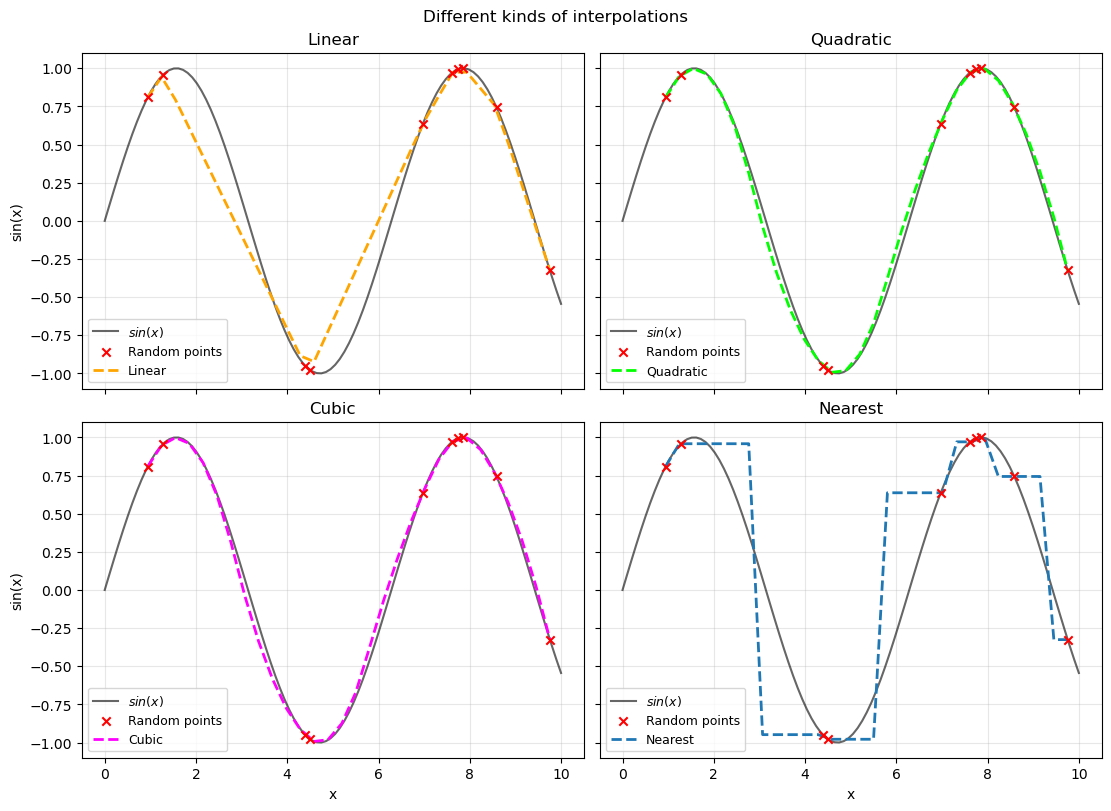

<Figure size 640x480 with 0 Axes>

In [2]:
# code here
# create a random set of x's
x_rand = rng.uniform(0, 10, size = 10)
# create a linspace of x for plotting the actual sine function
x_true = np.linspace(0,10,100, endpoint = True)

# in order to interpolate properly, we have to make sure that x is in increasing order.
x_rand.sort()

# putting into sine function from np lib
sinx_rand = np.sin(x_rand)
sinx_true = np.sin(x_true)

'''
We will be using interp1d from scipy.interpolate
'''

# kind: Linear
interp_linear = interpolate.interp1d(x_rand, sinx_rand, kind = 'linear')

# when making the new set of x for the interpolation, we have to make sure linspace is within the bounds of x_rand so that its 
# bounds will match with the interpolations
x_interp = np.linspace(x_rand.min(), x_rand.max(),30, endpoint = True)
y_interp_linear = interp_linear(x_interp)


# kind : Quadratic
interp_quad = interpolate.interp1d(x_rand, sinx_rand, kind = 'quadratic')
y_interp_quad = interp_quad(x_interp)


# kind: Cubic
interp_cubic = interpolate.interp1d(x_rand, sinx_rand, kind = 'cubic')
y_interp_cubic = interp_quad(x_interp)

# kind: Nearest
interp_nearest = interpolate.interp1d(x_rand, sinx_rand, kind = 'nearest')
y_interp_nearest = interp_nearest(x_interp)

# plotting the functions
# one figure, 2x2 grid: each panel compares one interpolation against the true sine
interpolations = [
    ('Linear', y_interp_linear, 'orange'),
    ('Quadratic', y_interp_quad, 'lime'),
    ('Cubic', y_interp_cubic, 'fuchsia'),
    ('Nearest', y_interp_nearest, 'tab:blue'),
]

fig, axes = plt.subplots(2, 2, figsize = (11, 8), sharex = True, sharey = True,
                         layout = 'constrained')

for ax, (name, y_interp, color) in zip(axes.flat, interpolations):
    ax.plot(x_true, sinx_true, label = r"$sin(x)$", color = 'black', alpha = 0.6)
    ax.scatter(x_rand, sinx_rand, marker = 'x', color = "red", label = "Random points", zorder = 4)
    ax.plot(x_interp, y_interp, linestyle = '--', color = color, linewidth = 2, label = name)
    ax.set_title(name)
    ax.grid(alpha = 0.3)
    ax.legend(loc = 'lower left', fontsize = 9)

# axis labels only on the outer panels
for ax in axes[-1]:
    ax.set_xlabel('x')
for ax in axes[:, 0]:
    ax.set_ylabel(r'sin(x)')

fig.suptitle("Different kinds of interpolations")
plt.show()
plt.savefig("problem1.png")

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [3]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [4]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

# load the data into np array
dow = np.loadtxt('dow.txt')

# now we sample the data
fraction = 0.10
n = len(dow)
sample_size = int(n * fraction)


# pick random indices
random_indices = np.random.choice(n, size = sample_size, replace = False)
sorted_indices = np.sort(random_indices)
sampled_dow = dow[sorted_indices]



# sampling the data
fractions = np.array([0.05, 0.10, 0.30, 0.50])
n = len(dow)
sample_sizes = n * fractions
sample_sizes = sample_sizes.astype(int)

'''
For random sampling of a time series data, we have to preseve its location in time, so we first have to 
pick random indices, sort it in ascending order, and then extract the data according to the indices

Also, the indices preserve the time of the sampled data when its time for it to be plotted.
'''

# pick random indices
sorted_indices_list = []
sampled_dow_list = []

for s in sample_sizes:
    random_indices = np.random.choice(n, size = s, replace = False)
    sorted_indices = np.sort(random_indices)
    sampled_dow = dow[sorted_indices]

    # store it in the array!
    '''
    sorted_indices_list = [5%, 10%, 30%, 50%]
    sampled_dows = [5%, 10%, 30%, 50%]
    '''
    sorted_indices_list.append(sorted_indices)
    sampled_dow_list.append(sampled_dow)

'''
example on how you would plot the samples

plt.plot(dow)
plt.plot(sorted_indices_list[1], sampled_dow_list[1]) --> for the 10%
'''

'\nexample on how you would plot the samples\n\nplt.plot(dow)\nplt.plot(sorted_indices_list[1], sampled_dow_list[1]) --> for the 10%\n'

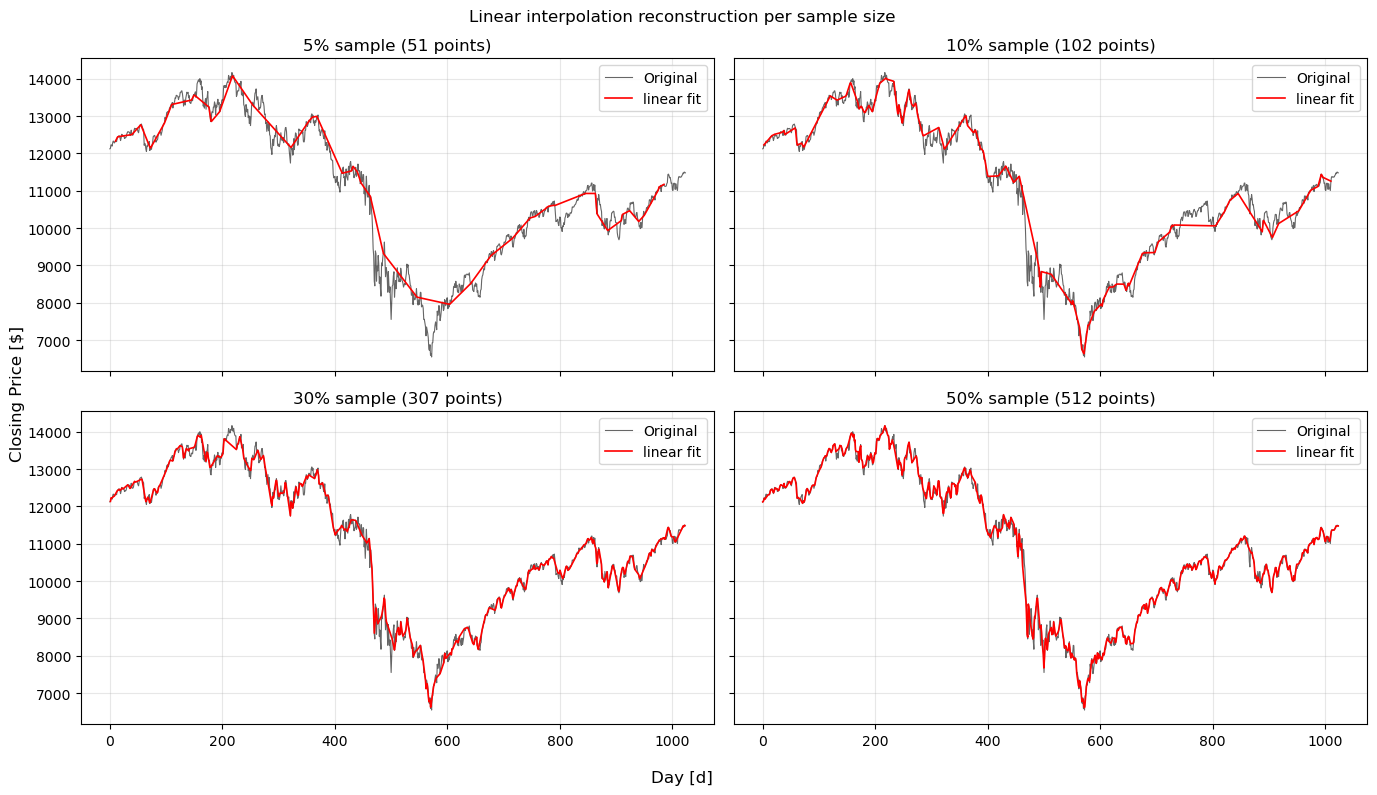

<Figure size 640x480 with 0 Axes>

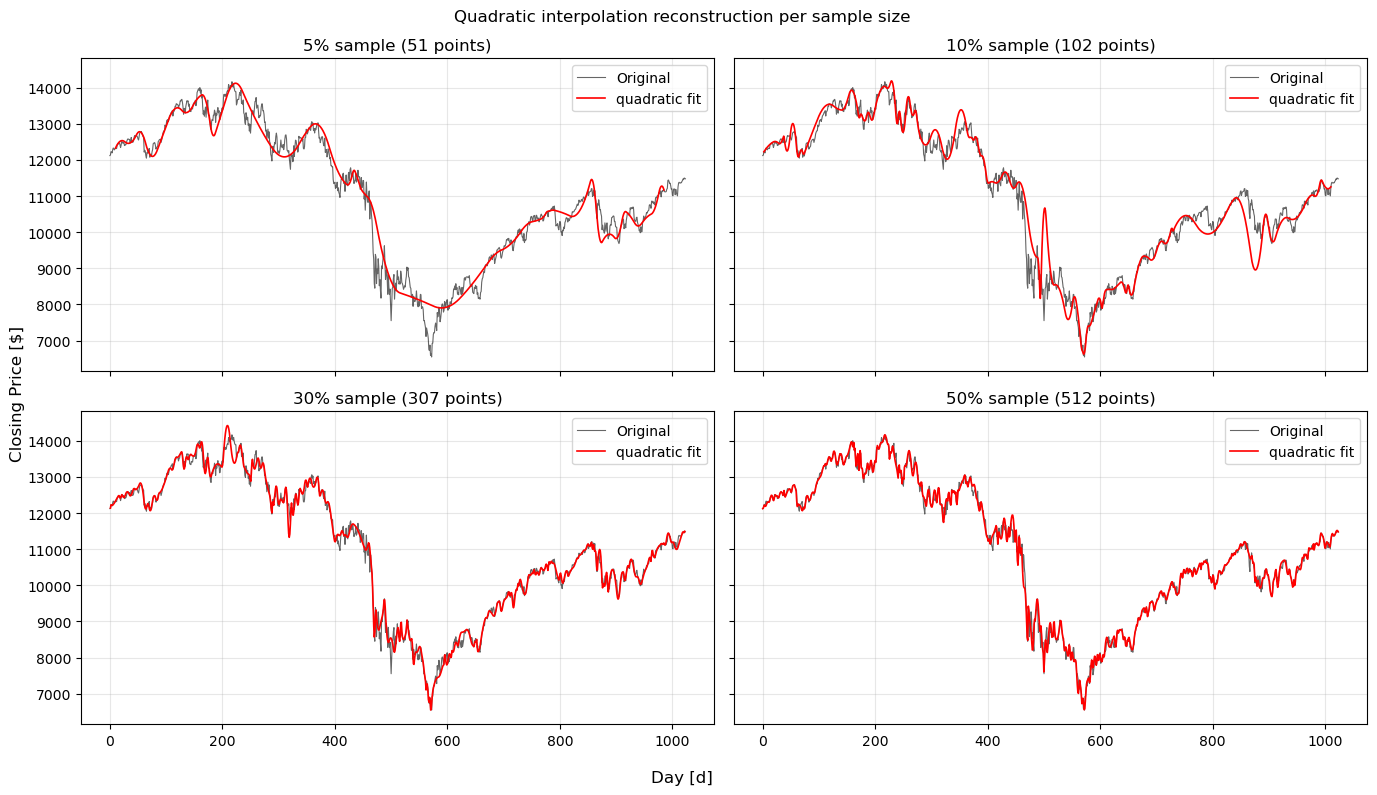

<Figure size 640x480 with 0 Axes>

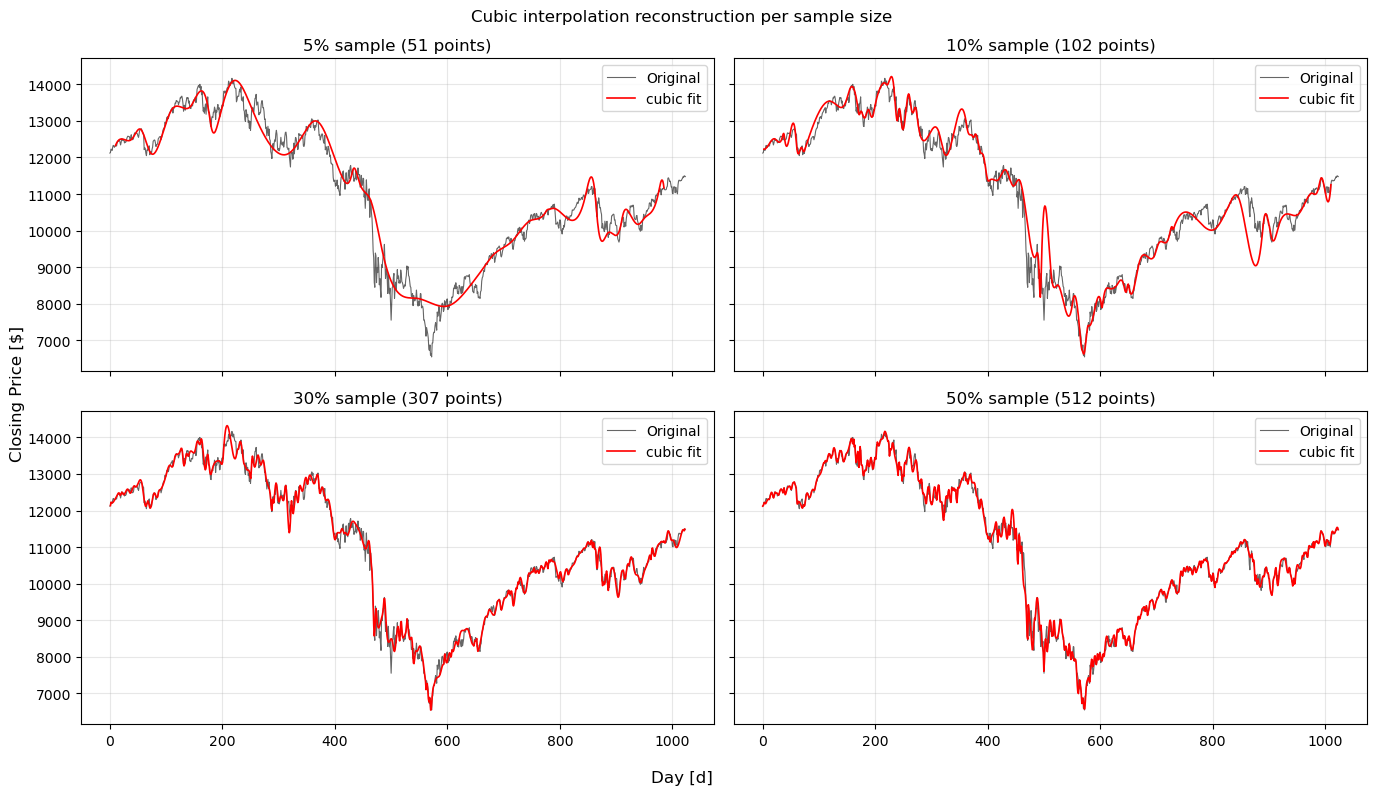

<Figure size 640x480 with 0 Axes>

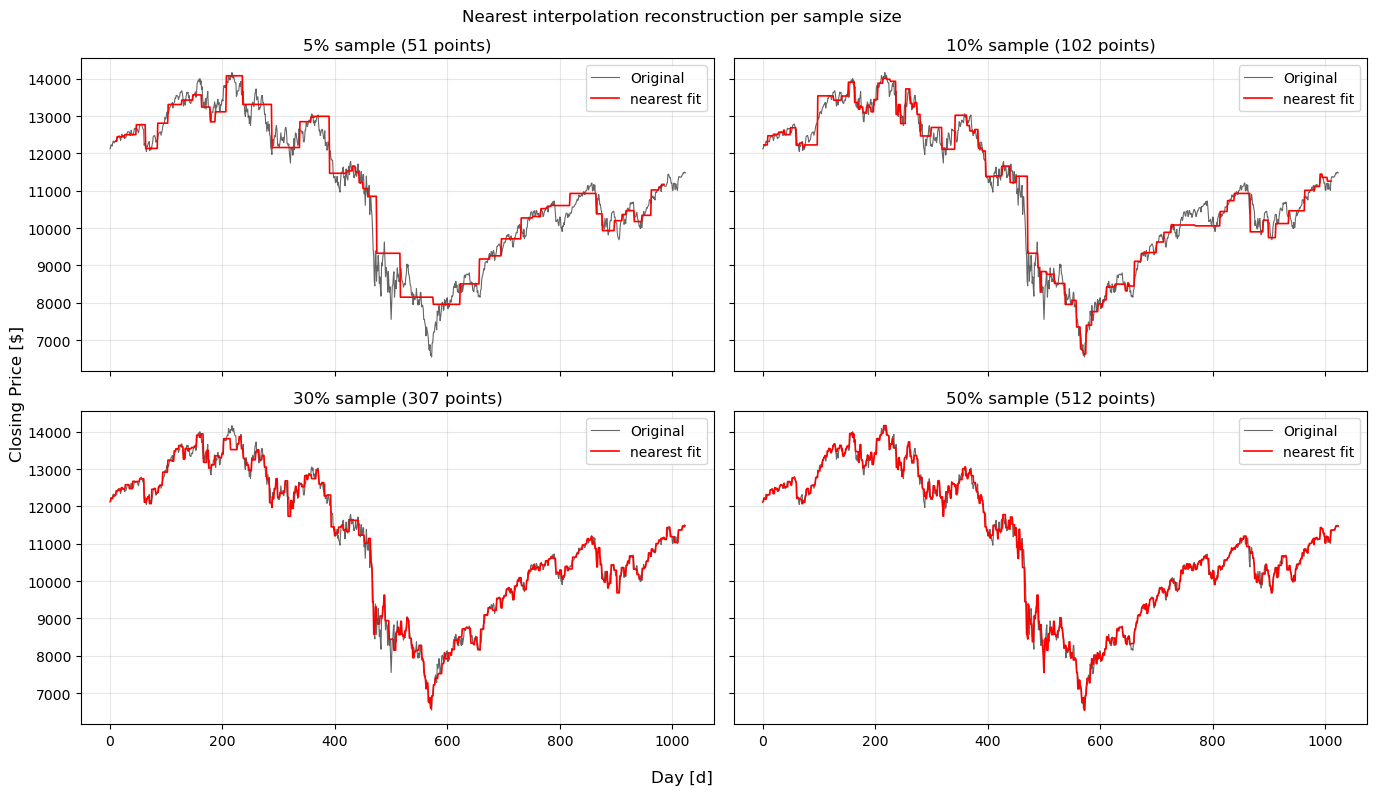

<Figure size 640x480 with 0 Axes>

In [5]:
'''
Reconstructing
'''

# the kinds of interpolation we will be using
kinds = ['linear', 'quadratic', 'cubic', 'nearest']
sample_labels = ['5%', '10%', '30%', '50%']

# big outer list so that its easier to plot
'''
x_interp_list = [[5%], [10%], [30%], [50%]] qwrty
'''
x_interp_list = []
# dictionary to keep track of what kind of interpolation was used
y_interp = {kind: [] for kind in kinds} 

for data, index in zip(sampled_dow_list, sorted_indices_list):
    # make sure that the x interpolations match the bounds, like in problem 1
    x_interp = np.linspace(index.min(), index.max(), 1000, endpoint=True)
    x_interp_list.append(x_interp)

    # for every listed interpolation in kinds, try it on the data
    for kind in kinds:
        interp = interpolate.interp1d(index, data, kind=kind)
        y_interp[kind].append(interp(x_interp))

# plotting (grouped by interpolation kind)
# so for every kinds in the kinds listed
for kind in kinds:
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, sharey=True)

    '''
    axes.flat 2D arrays as if it were 1D arrays, so for the subplots shaped like a 2b2 matrix, we don't have to use 
    two for loops to plot
    enumerate is used to call our data from y_interp by index.
    '''
    for i, (ax, label) in enumerate(zip(axes.flat, sample_labels)):
        # original time-series for reference
        ax.plot(np.arange(n), dow, color='black', alpha=0.6, lw=0.8, label='Original')

        # interpolated reconstruction
        ax.plot(x_interp_list[i], y_interp[kind][i], color='red', lw=1.2, label=f'{kind} fit')
        ax.set_title(f'{label} sample ({len(sampled_dow_list[i])} points)')
        ax.grid(alpha=0.3)
        ax.legend()
        
    fig.supxlabel('Day [d]')
    fig.supylabel('Closing Price [$]')
    fig.suptitle(f'{kind.capitalize()} interpolation reconstruction per sample size')
    fig.tight_layout()
    plt.show()
    plt.savefig(f"problem2_{kind}.png")

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

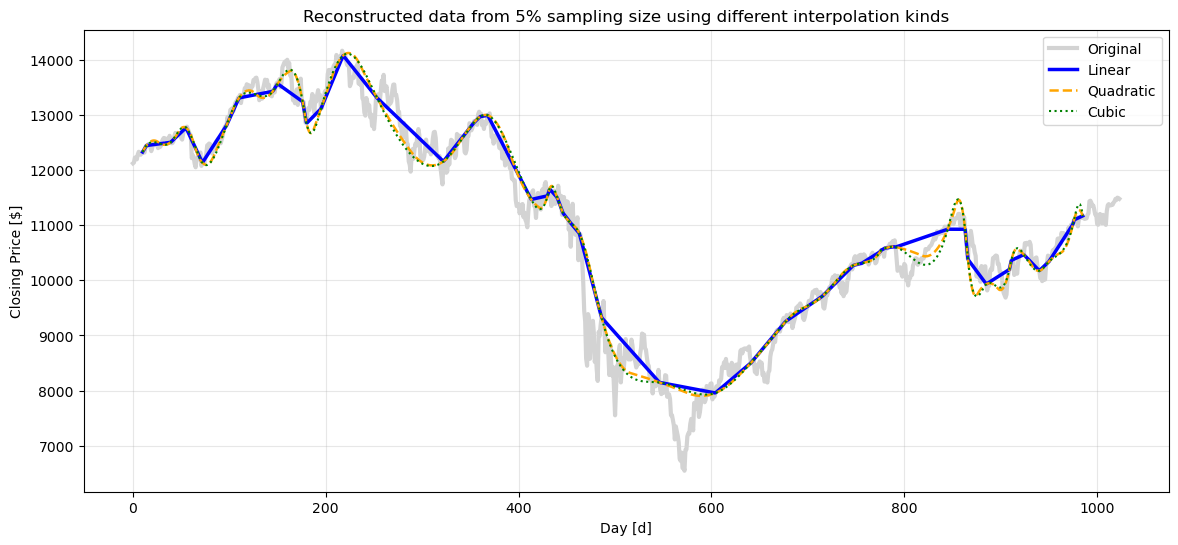

In [6]:
# code here
'''
We will use the 5% data sample
'''
plt.figure(figsize=(14, 6))

plt.plot(np.arange(n), dow, color = 'lightgray', alpha = 1, lw = 3, label = 'Original')
plt.plot(x_interp_list[0], y_interp['linear'][0], alpha = 1, lw = 2.5, linestyle = '-', color = 'blue', label = "Linear")
plt.plot(x_interp_list[0], y_interp['quadratic'][0], alpha = 1, lw = 1.8, linestyle = '--', color = 'orange', label = "Quadratic")
plt.plot(x_interp_list[0], y_interp['cubic'][0], alpha = 1, lw = 1.5, linestyle = ':', color = 'green', label = "Cubic")

plt.grid(alpha = 0.3)
plt.legend()
plt.ylabel("Closing Price [$]")
plt.xlabel("Day [d]")
plt.title("Reconstructed data from 5% sampling size using different interpolation kinds")
plt.savefig('problem3.png')
plt.show()

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---